# 06 · Opening up the denoiser

**Kaggle · GPU T4 (CPU works too, slower) · Internet ON** (installs YOLO for the failure gallery). About 10 minutes.

Goal: explain *what* the trained DnCNN learned and *why* it behaved as it did in notebooks 04 and 05, with five
probes: (1) first-layer filters, (2) receptive field in theory and measured, (3) frequency response, (4) the
predicted residual on in- and out-of-distribution inputs, (5) a failure gallery of images where restoration hurt
detection. This is the interpretability part of the project.

**Inputs** (Add Input): notebook **04** (`dncnn_last.pt`), notebook **05** (`per_image_ap.csv`, `subset_ids.json`),
notebook **01** (`degradations.py`, `best_classical.json`) and the **BSD500** dataset (validation images).

In [4]:
import os, sys, glob, json, io, contextlib
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import cv2
import pandas as pd

def find_input(name, required=True):
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    if not hits and required:
        raise FileNotFoundError(f"{name} not found under /kaggle/input: add the notebook that produced it as an input")
    return hits[0] if hits else None

sys.path.insert(0, os.path.dirname(find_input("degradations.py")))
from degradations import DEGRADATIONS, degrade
BEST = json.load(open(find_input("best_classical.json")))
# BSD500 validation images, wherever the dataset is mounted
val_dirs = [d for d in sorted(glob.glob("/kaggle/input/**/images/val", recursive=True)) if glob.glob(f"{d}/*.jpg")]
assert val_dirs, ("BSD500 validation images not found: Add Input -> Datasets -> search "
                  "'berkeley segmentation dataset 500' (balraj98), the same dataset as notebook 04")
BSD_VAL = val_dirs[0]
val_paths = sorted(glob.glob(f"{BSD_VAL}/*.jpg"))
load_rgb = lambda p: cv2.imread(p, cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32) / 255.0
test_imgs = [load_rgb(p) for p in val_paths][4:]          # the same 96 test images as notebooks 01 and 04
assert len(test_imgs) == 96, f"expected 100 BSD500 val images in {BSD_VAL}, found {len(val_paths)}"
OUT_DIR = "/kaggle/working/outputs/06"; os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

class DnCNN(nn.Module):                                    # exactly as in notebook 04
    def __init__(self, channels=3, depth=17, features=64):
        super().__init__()
        layers = [nn.Conv2d(channels, features, kernel_size=3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False),
                       nn.BatchNorm2d(features), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(features, channels, kernel_size=3, padding=1)]
        self.body = nn.Sequential(*layers)
    def forward(self, y):
        return self.body(y)

def resolve_checkpoint():
    """Find the DnCNN checkpoint. A .pt file is a zip archive, and Kaggle unzips zip files uploaded as a
    dataset, so an uploaded dncnn_last.pt can arrive as a folder holding data.pkl. Rebuild the file if so."""
    pts = sorted(glob.glob("/kaggle/input/**/*.pt", recursive=True) + glob.glob("/kaggle/input/**/*.pth", recursive=True))
    if pts:
        return pts[0]
    pkls = sorted(glob.glob("/kaggle/input/**/data.pkl", recursive=True))
    assert pkls, "no checkpoint under /kaggle/input: attach notebook 04 (Add Input -> Your Work -> Notebooks)"
    import zipfile
    root, out = os.path.dirname(pkls[0]), "/kaggle/working/dncnn_last.pt"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as z:      # torch expects uncompressed records under one folder
        for dirpath, _, files in os.walk(root):
            for f in sorted(files):
                full = os.path.join(dirpath, f)
                z.write(full, os.path.join("archive", os.path.relpath(full, root)))
    print(f"rebuilt {out} from the unpacked folder {root}")
    return out

ck = torch.load(resolve_checkpoint(), map_location=device, weights_only=False)
model = DnCNN(ck["cfg"]["channels"], ck["cfg"]["depth"], ck["cfg"]["features"]).to(device)
model.load_state_dict(ck["model"]); model.eval()
DEPTH = ck["cfg"]["depth"]

@torch.no_grad()
def residual(img):
    """Predicted noise for a float RGB (H, W, 3) image in [0, 1]."""
    y = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).unsqueeze(0).to(device)
    return model(y)[0].permute(1, 2, 0).float().cpu().numpy()

def denoise(img):
    return np.clip(img - residual(img), 0, 1).astype(np.float32)

def psnr(a, b):
    return 10 * np.log10(1.0 / np.mean((a.astype(np.float64) - b) ** 2))

def noisy_like_nb01(clean, i, sigma):
    """Same noise as notebooks 01 and 04 for test image i."""
    levels = DEGRADATIONS["gaussian"][1]
    sev = levels.index(sigma) if sigma in levels else 100 + int(sigma)
    rng = np.random.default_rng([0, i, list(DEGRADATIONS).index("gaussian"), sev])
    return np.clip(clean + rng.normal(0, sigma / 255, clean.shape), 0, 1).astype(np.float32)

print(f"{len(test_imgs)} test images; DnCNN depth {DEPTH}, trained {ck['epoch'] + 1} epochs; device {device}")

rebuilt /kaggle/working/dncnn_last.pt from the unpacked folder /kaggle/input/datasets/shourjabanerjee/dcnn-last/dncnn_last
96 test images; DnCNN depth 17, trained 50 epochs; device cuda


## 1 · First-layer filters

Plot all 64 first-layer kernels (3×3×3 each — show them as tiny RGB images after normalising, and also per
channel). Then compare them to classical kernels: correlate each learned filter (averaged over colour) with a
3×3 Gaussian, Laplacian, and Sobel-x / Sobel-y, and report the best match for each.

A 3×3 kernel is small, so be honest about how much you can read into it — that's a good point for the write-up.

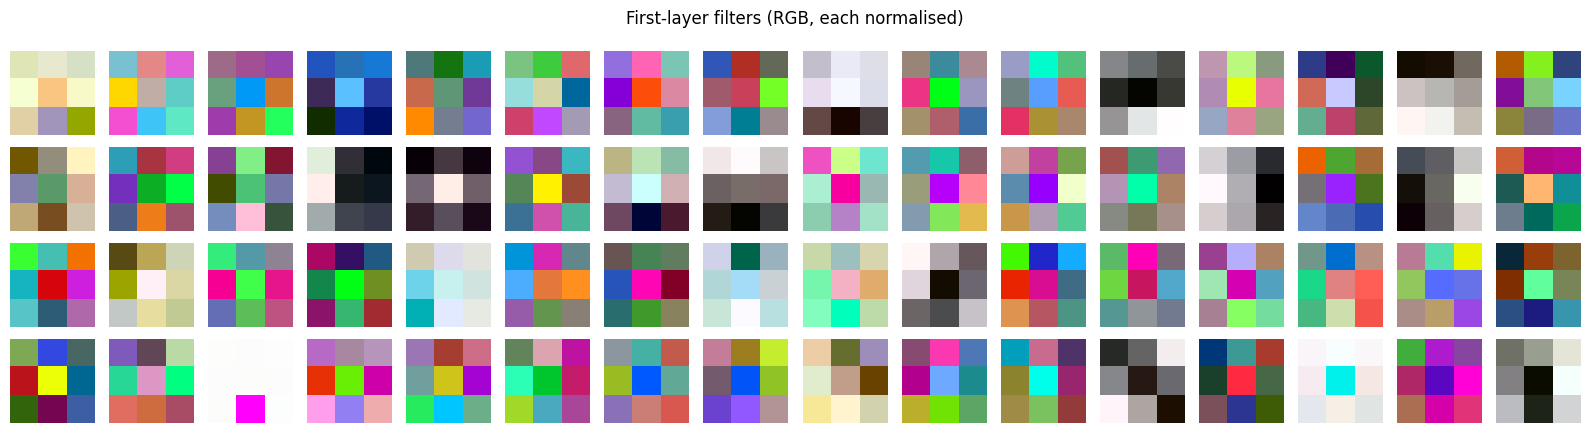

9 of 64 filters are close (|cosine| >= 0.8) to a classical kernel:
best_match
Sobel y (horizontal edges)           3
Sobel x (vertical edges)             3
Laplacian (edges, all directions)    1
Gaussian (low-pass)                  1
identity (centre pixel)              1

colour share = energy in differences BETWEEN channels: median 0.79; 43 filters are mostly colour-opponent (> 0.5), e.g. R minus G


In [5]:
w1 = model.body[0].weight.detach().cpu().numpy()        # (64, 3, 3, 3): 64 filters over R, G, B

# (a) All 64 filters as tiny RGB images (each normalised to its own range)
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for f, ax in enumerate(axes.ravel()):
    k = w1[f].transpose(1, 2, 0)
    ax.imshow((k - k.min()) / (k.max() - k.min() + 1e-12), interpolation="nearest"); ax.axis("off")
plt.suptitle("First-layer filters (RGB, each normalised)"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/filters.png", dpi=150); plt.show()

# (b) Compare each filter (averaged over colour) with classical 3x3 kernels, by cosine similarity
def unit(k): return k / (np.linalg.norm(k) + 1e-12)
KERNELS = {
    "Gaussian (low-pass)": np.outer([1, 2, 1], [1, 2, 1]) / 16.0,
    "Laplacian (edges, all directions)": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float),
    "Sobel x (vertical edges)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    "Sobel y (horizontal edges)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    "identity (centre pixel)": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
}
def match_filters(w):
    rows = []
    for f in range(w.shape[0]):
        lum = w[f].mean(axis=0)
        sims = {name: float(np.sum(unit(lum) * unit(K))) for name, K in KERNELS.items()}
        best = max(sims, key=lambda n: abs(sims[n]))
        colour = np.sum((w[f] - w[f].mean(0, keepdims=True)) ** 2) / (np.sum(w[f] ** 2) + 1e-12)
        rows.append(dict(filter=f, best_match=best, cosine=sims[best], colour_share=colour))
    return pd.DataFrame(rows)

fm = match_filters(w1)
fm.to_csv(f"{OUT_DIR}/filter_matches.csv", index=False)
strong = fm[fm.cosine.abs() >= 0.8]
print(f"{len(strong)} of 64 filters are close (|cosine| >= 0.8) to a classical kernel:")
print(strong.best_match.value_counts().to_string())
print(f"\ncolour share = energy in differences BETWEEN channels: median {fm.colour_share.median():.2f}; "
      f"{(fm.colour_share > 0.5).sum()} filters are mostly colour-opponent (> 0.5), e.g. R minus G")
# Write-up: a 3x3 kernel has only 9 numbers per channel, so "looks like Sobel" is a loose statement;
# what is solid is the split between smooth (low-pass), edge (derivative) and colour-difference filters.

## 2 · Receptive field: theory vs measurement

**Theory:** for $D$ stacked 3×3 convolutions with stride 1, derive the receptive field $R(D)$
(hint: each layer adds 2). Fill in `rf_theory` and check it gives 35 for $D = 17$.

**Measurement:** the *effective* receptive field is usually much smaller than the theoretical one. Measure it:
take a noisy image, compute the gradient of the **centre output pixel** with respect to the input, and plot
$|\partial y_{c}/\partial x|$ as a heatmap. Report the radius that contains, say, 90% of the gradient mass.

sigma 15: 90% of the gradient mass lies within +-7 px (theoretical RF +-17); mass outside the 35x35 box = 0.0e+00 (must be 0)
sigma 25: 90% of the gradient mass lies within +-7 px (theoretical RF +-17); mass outside the 35x35 box = 1.1e-07 (must be 0)
sigma 50: 90% of the gradient mass lies within +-10 px (theoretical RF +-17); mass outside the 35x35 box = 0.0e+00 (must be 0)


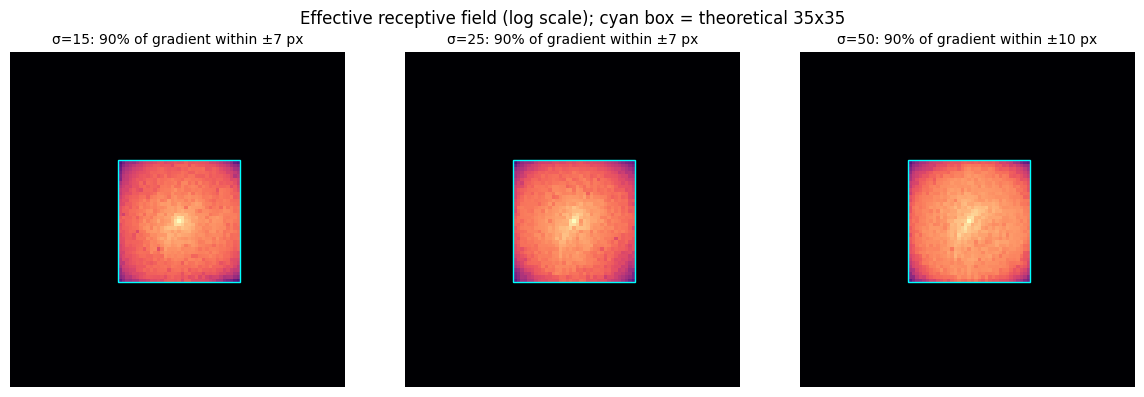

In [6]:
def rf_theory(depth, k=3):
    """Each stride-1 k x k layer widens the receptive field by k - 1 pixels."""
    return 1 + depth * (k - 1)

assert rf_theory(17) == 35

def effective_rf(img, sigma, crop=96):
    """|d output_center / d input|, summed over channels, for a noisy crop. Shape (crop, crop)."""
    clean = img[:crop, :crop]
    noisy = np.clip(clean + np.random.default_rng(0).normal(0, sigma / 255, clean.shape), 0, 1).astype(np.float32)
    x = torch.from_numpy(noisy.transpose(2, 0, 1)).unsqueeze(0).to(device).requires_grad_(True)
    out = model(x)                                            # eval mode: BatchNorm uses running stats
    c = crop // 2
    out[0, :, c, c].sum().backward()
    return x.grad[0].abs().sum(0).cpu().numpy()

def mass_radius(g, frac=0.9):
    """Half-width r of the smallest centred square holding `frac` of the gradient mass."""
    c = g.shape[0] // 2
    total = g.sum()
    for r in range(c + 1):
        if g[c - r:c + r + 1, c - r:c + r + 1].sum() >= frac * total:
            return r
    return c

R = rf_theory(DEPTH); half = R // 2
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, s in zip(axes, (15, 25, 50)):
    g = effective_rf(test_imgs[0], s)
    c = g.shape[0] // 2
    outside = g.sum() - g[c - half:c + half + 1, c - half:c + half + 1].sum()
    r90 = mass_radius(g)
    ax.imshow(np.log10(g + 1e-12), cmap="magma"); ax.set_title(f"σ={s}: 90% of gradient within ±{r90} px", fontsize=10)
    ax.add_patch(plt.Rectangle((c - half - 0.5, c - half - 0.5), R, R, fill=False, ec="cyan", lw=1))
    ax.axis("off")
    print(f"sigma {s}: 90% of the gradient mass lies within +-{r90} px (theoretical RF +-{half}); "
          f"mass outside the {R}x{R} box = {outside / g.sum():.1e} (must be 0)")
plt.suptitle(f"Effective receptive field (log scale); cyan box = theoretical {R}x{R}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/receptive_field.png", dpi=150); plt.show()

## 3 · Frequency response

Compare the **radially averaged power spectrum** of clean, noisy, and denoised images. White Gaussian noise has a
flat spectrum while natural images fall off roughly as $1/f^2$, so the denoiser should mostly remove high
frequencies. Plot the ratio $P_{\text{denoised}}(f) / P_{\text{noisy}}(f)$ — an empirical transfer function —
at σ = 15, 25, 50, and on the same plot the ratio for your best classical filter.

**Write-up prompt:** is DnCNN behaving like a fixed low-pass filter, or does its "cutoff" adapt to the noise level
and to image content? Your plot answers this.

sigma 15: frequency where output power drops below half the noisy power: DnCNN 0.355, classical (bilateral) 0.293 cycles/pixel
sigma 25: frequency where output power drops below half the noisy power: DnCNN 0.254, classical (bilateral) 0.137 cycles/pixel
sigma 50: frequency where output power drops below half the noisy power: DnCNN 0.152, classical (gaussian) 0.098 cycles/pixel


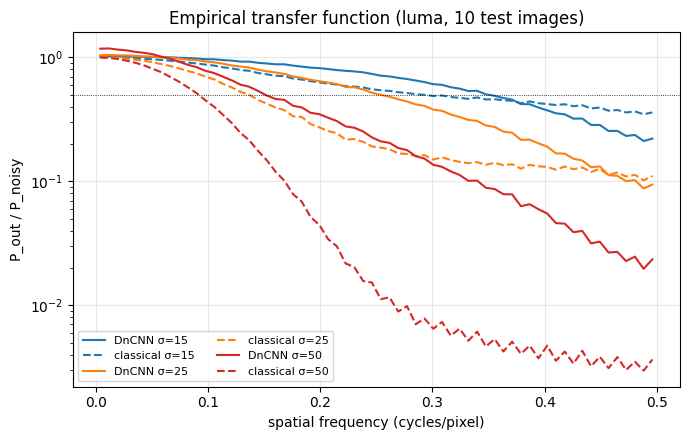

In [7]:
def radial_power_spectrum(gray, n_bins=64):
    """gray (H, W) -> (frequency in cycles/pixel, mean power in rings of |f|)."""
    F = np.fft.fftshift(np.fft.fft2(gray - gray.mean()))
    P = np.abs(F) ** 2
    fy = np.fft.fftshift(np.fft.fftfreq(gray.shape[0])); fx = np.fft.fftshift(np.fft.fftfreq(gray.shape[1]))
    r = np.sqrt(fy[:, None] ** 2 + fx[None, :] ** 2)
    edges = np.linspace(0, 0.5, n_bins + 1)
    idx = np.digitize(r.ravel(), edges) - 1
    keep = (idx >= 0) & (idx < n_bins)
    power = np.bincount(idx[keep], P.ravel()[keep], n_bins) / np.maximum(np.bincount(idx[keep], minlength=n_bins), 1)
    return (edges[:-1] + edges[1:]) / 2, power

def luma(img): return img @ np.array([0.299, 0.587, 0.114], np.float32)

def classical_gauss(img, sigma):
    """Notebook 01's tuned classical filter for Gaussian noise at this sigma."""
    e = BEST["gaussian"][str(sigma)]
    if e["filter"] == "bilateral":
        return np.clip(cv2.bilateralFilter(img, 7, e["params"]["sigma_color"], e["params"]["sigma_space"]), 0, 1)
    if e["filter"] == "gaussian":
        return np.clip(cv2.GaussianBlur(img, (0, 0), e["params"]["sigma"]), 0, 1)
    if e["filter"] == "median":
        return cv2.medianBlur((img * 255).round().astype(np.uint8), e["params"]["k"]).astype(np.float32) / 255
    return cv2.fastNlMeansDenoisingColored((img * 255).round().astype(np.uint8), None, e["params"]["h"], e["params"]["h"], 7, 21).astype(np.float32) / 255

def transfer(denoise_fn, sigma, n=10):
    """Empirical transfer function P_out(f) / P_noisy(f), averaged over n test images."""
    ratios = []
    for i, clean in enumerate(test_imgs[:n]):
        noisy = noisy_like_nb01(clean, i, sigma)
        f, p_noisy = radial_power_spectrum(luma(noisy)); _, p_out = radial_power_spectrum(luma(denoise_fn(noisy)))
        ratios.append(p_out / p_noisy)
    return f, np.mean(ratios, axis=0)

def cutoff(f, ratio, level=0.5):
    """Lowest frequency where the transfer function falls below `level`."""
    below = np.flatnonzero(ratio < level)
    return f[below[0]] if below.size else np.nan

fig, ax = plt.subplots(figsize=(7, 4.5))
for s, col in zip((15, 25, 50), ("#1f77b4", "#ff7f0e", "#d62728")):
    f, t_d = transfer(denoise, s); _, t_c = transfer(lambda im: classical_gauss(im, s), s)
    ax.semilogy(f, t_d, color=col, label=f"DnCNN σ={s}"); ax.semilogy(f, t_c, "--", color=col, label=f"classical σ={s}")
    print(f"sigma {s}: frequency where output power drops below half the noisy power: "
          f"DnCNN {cutoff(f, t_d):.3f}, classical ({BEST['gaussian'][str(s)]['filter']}) {cutoff(f, t_c):.3f} cycles/pixel")
ax.axhline(0.5, color="k", lw=0.6, ls=":"); ax.set_xlabel("spatial frequency (cycles/pixel)"); ax.set_ylabel("P_out / P_noisy")
ax.set_title("Empirical transfer function (luma, 10 test images)"); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/transfer_function.png", dpi=150); plt.show()
# Write-up: if the cutoff moves to lower frequencies as sigma grows, the network adapts its smoothing to the noise
# level it infers, which a fixed filter cannot do unless it is re-tuned for each sigma.

## 4 · The predicted residual

The model outputs an estimate of the noise. On Gaussian inputs it should look like white noise (check the
histogram against a Gaussian with the true σ, and its spectrum should be flat). Then feed it **out-of-distribution**
inputs — salt-and-pepper, JPEG at quality 10, blur — and show what it "thinks" the noise is. Structure (edges,
texture) leaking into the residual is exactly the failure mode you should connect to the mAP results in notebook 05.

                  psnr_in  psnr_out   leak  res_std  gain_db
input                                                       
gaussian 25        20.547    31.107 -0.021   22.696    10.56
salt_pepper 0.05   17.915    18.154 -0.007    9.566     0.24
jpeg 10            25.646    24.564  0.052   51.705    -1.08
blur 2.0           24.311    22.579  0.046  156.949    -1.73
low_light 0.8       8.683     8.584  0.053   11.825    -0.10

sigma 25: predicted residual std 21.4 vs true noise std 23.0 (0-255 scale); correlation with the true noise 0.935


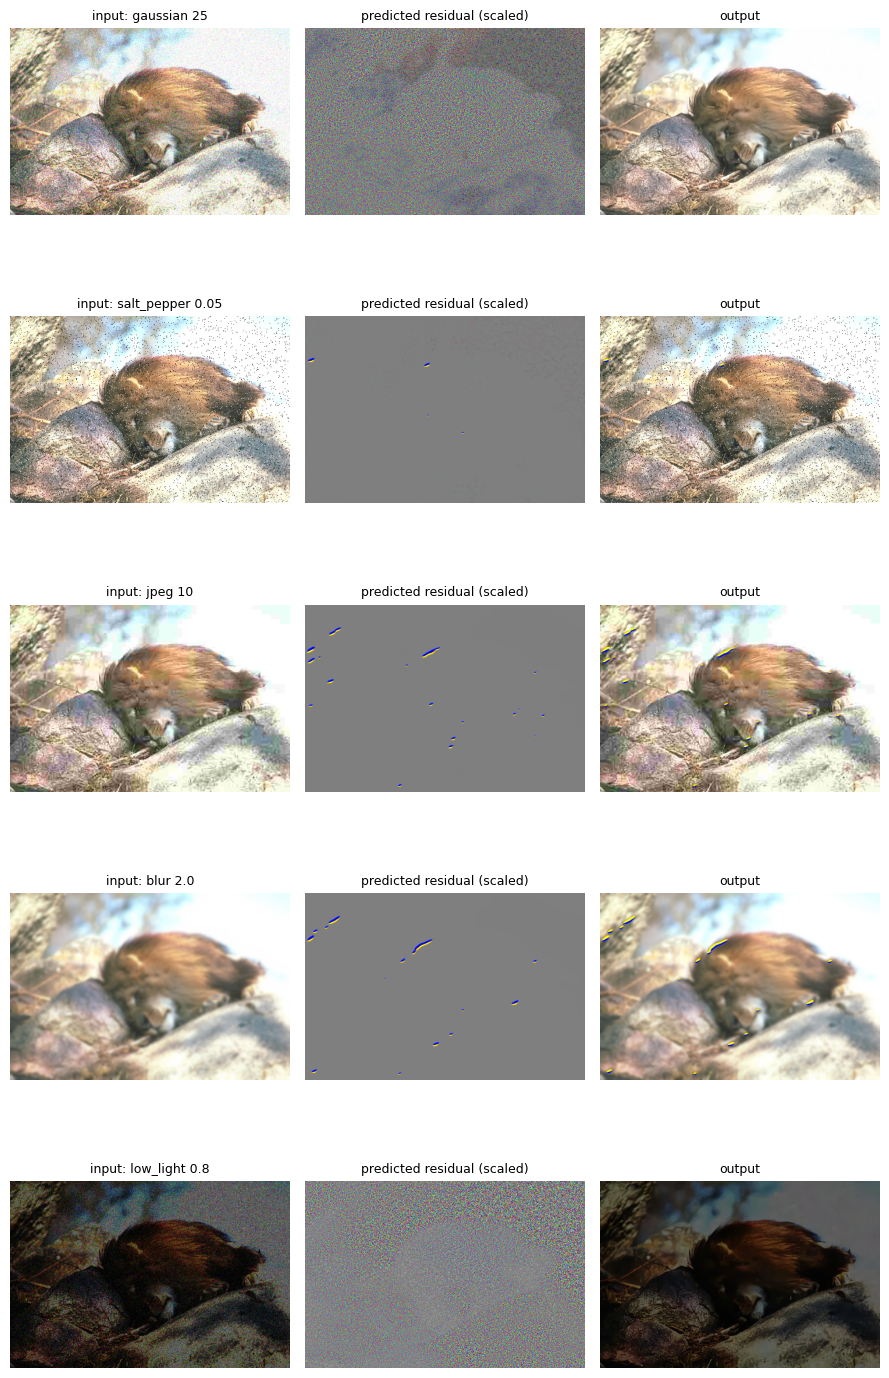

In [8]:
def edge_strength(clean):
    gx = cv2.Sobel(luma(clean), cv2.CV_32F, 1, 0); gy = cv2.Sobel(luma(clean), cv2.CV_32F, 0, 1)
    return np.sqrt(gx ** 2 + gy ** 2)

def structure_leak(clean, res):
    """Correlation between |predicted residual| and the clean image's edge strength.
    About 0 = the residual looks like noise; high = the network is removing image structure."""
    return float(np.corrcoef(np.abs(res).sum(-1).ravel(), edge_strength(clean).ravel())[0, 1])

PROBES = [("gaussian", 25), ("salt_pepper", 0.05), ("jpeg", 10), ("blur", 2.0), ("low_light", 0.8)]
rows, gallery = [], []
for name, s in PROBES:
    for i, clean in enumerate(test_imgs[:20]):
        inp = degrade(clean, name, s, np.random.default_rng([0, i, 7]))
        res = residual(inp); out = np.clip(inp - res, 0, 1)
        rows.append(dict(input=f"{name} {s}", psnr_in=psnr(clean, inp), psnr_out=psnr(clean, out),
                         leak=structure_leak(clean, res), res_std=float(res.std() * 255)))
        if i == 0:
            gallery.append((f"{name} {s}", inp, res, out))
probe = pd.DataFrame(rows).groupby("input", sort=False).mean().round(3)
probe["gain_db"] = (probe.psnr_out - probe.psnr_in).round(2)
print(probe.to_string())
probe.to_csv(f"{OUT_DIR}/residual_probes.csv")

# Is the residual on Gaussian input really Gaussian noise of the right size?
clean = test_imgs[0]; noisy = noisy_like_nb01(clean, 0, 25); res = residual(noisy); true_noise = noisy - clean
print(f"\nsigma 25: predicted residual std {res.std() * 255:.1f} vs true noise std {true_noise.std() * 255:.1f} (0-255 scale); "
      f"correlation with the true noise {np.corrcoef(res.ravel(), true_noise.ravel())[0, 1]:.3f}")

fig, axes = plt.subplots(len(gallery), 3, figsize=(9, 3 * len(gallery)))
for row, (title, inp, res, out) in zip(axes, gallery):
    sc = 3 * res.std() + 1e-6
    for ax, im, t in zip(row, [inp, 0.5 + res / (2 * sc), out], [f"input: {title}", "predicted residual (scaled)", "output"]):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/residual_probes.png", dpi=120); plt.show()
# Write-up: on Gaussian input the residual is structureless noise (leak ~ 0). On blur or JPEG the network still
# "finds noise", but its residual traces edges and block boundaries: it removes structure, and PSNR can drop.

## 5 · Failure gallery

Notebook 05 only stores aggregate mAP, so pick one or two interesting conditions and compute **per-image AP**
(run `COCOeval` with `params.imgIds = [one_id]`, reusing `detect()` from notebook 05). Find the images with the
largest drop after restoration vs before (or the largest gap between DnCNN and classical). Show 4–6 of them: clean, degraded, restored, with detections drawn.
Write one sentence per image on *why* it failed.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
sigma 50: DnCNN had higher PSNR than classical on 100% of images, yet lower AP on 40 of them (13%): higher PSNR, worse detection
          ap_none  ap_classical  ap_dncnn  psnr_classical  psnr_dncnn
image_id                                                             
353970      0.250         0.700     0.238          27.231      31.733
315257      0.000         0.800     0.367          23.697      28.800
210099      0.125         0.367     0.050          20.583      28.586
545129      0.608         0.000     0.955          19.923      26.290


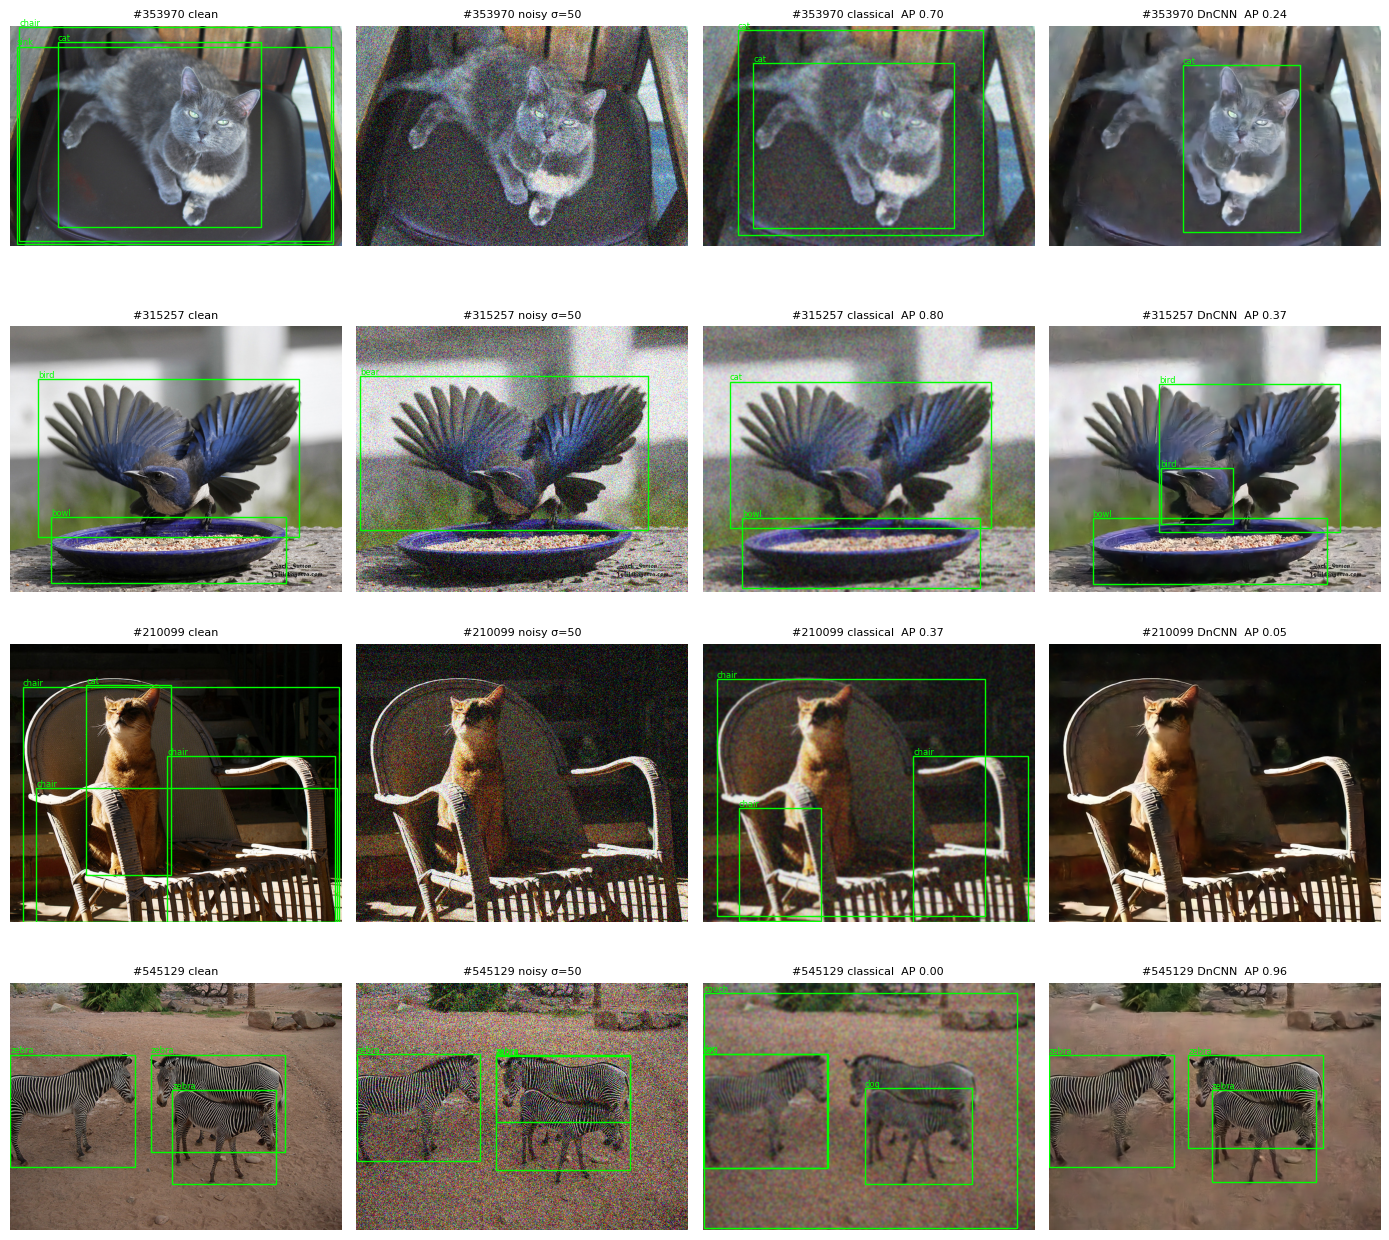

In [9]:
!pip -q install ultralytics pycocotools
from ultralytics import YOLO
from pycocotools.coco import COCO

per_img = pd.read_csv(find_input("per_image_ap.csv"))
img_ids = json.load(open(find_input("subset_ids.json")))

# Which images were hurt most? Gaussian sigma = 50: DnCNN vs classical, and DnCNN vs no restoration
w = per_img[(per_img.degradation == "gaussian") & (per_img.severity == 50)].pivot(index="image_id", columns="restorer", values=["ap", "psnr"])
w.columns = [f"{a}_{b}" for a, b in w.columns]
w["dncnn_minus_classical_ap"] = w.ap_dncnn - w.ap_classical
w["dncnn_minus_classical_psnr"] = w.psnr_dncnn - w.psnr_classical
paradox = w[(w.dncnn_minus_classical_psnr > 0) & (w.dncnn_minus_classical_ap < 0)].sort_values("dncnn_minus_classical_ap")
print(f"sigma 50: DnCNN had higher PSNR than classical on {(w.dncnn_minus_classical_psnr > 0).mean():.0%} of images, "
      f"yet lower AP on {len(paradox)} of them ({len(paradox) / len(w):.0%}): higher PSNR, worse detection")
picks = list(paradox.index[:3]) + list(w.sort_values("dncnn_minus_classical_ap").index[-1:])   # 3 worst + 1 best case
print(w.loc[picks, ["ap_none", "ap_classical", "ap_dncnn", "psnr_classical", "psnr_dncnn"]].round(3).to_string())

# Recreate exactly the images notebook 05 scored (same seeds), restore, detect, draw
COCO_ANN = find_input("instances_val2017.json", required=False)
if COCO_ANN is None:
    os.makedirs("/kaggle/working/coco", exist_ok=True)
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -O /kaggle/working/coco/ann.zip && unzip -q -o /kaggle/working/coco/ann.zip -d /kaggle/working/coco
    COCO_ANN = "/kaggle/working/coco/annotations/instances_val2017.json"
with contextlib.redirect_stdout(io.StringIO()):
    coco = COCO(COCO_ANN)
detector = YOLO("yolov8n.pt")

def load_coco(iid):
    info = coco.loadImgs(iid)[0]
    local = find_input(info["file_name"], required=False)
    if local is None:                                   # fetch just this image
        local = f"/kaggle/working/{info['file_name']}"
        if not os.path.exists(local):
            os.system(f"wget -q {info['coco_url']} -O {local}")
    return load_rgb(local)

def classical_restore(img, name, s):
    e = BEST[name][str(s)]
    return img if e["filter"] == "none" else classical_gauss(img, s) if name == "gaussian" else img

def draw(ax, img, title):
    r = detector.predict(np.ascontiguousarray((img[:, :, ::-1] * 255).round().astype(np.uint8)), conf=0.25, verbose=False)[0]
    ax.imshow(img); ax.set_title(title, fontsize=8); ax.axis("off")
    for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1))
        ax.text(x1, y1, detector.names[c], color="lime", fontsize=6, va="bottom")

sev_idx = DEGRADATIONS["gaussian"][1].index(50); deg_idx = list(DEGRADATIONS).index("gaussian")
fig, axes = plt.subplots(len(picks), 4, figsize=(14, 3.3 * len(picks)))
for row, iid in zip(axes, picks):
    k = img_ids.index(iid); clean = load_coco(iid)
    noisy = degrade(clean, "gaussian", 50, np.random.default_rng([0, k, deg_idx, sev_idx]))   # as in notebook 05
    for ax, im, t in zip(row, [clean, noisy, classical_restore(noisy, "gaussian", 50), denoise(noisy)],
                         ["clean", "noisy σ=50", f"classical  AP {w.loc[iid, 'ap_classical']:.2f}", f"DnCNN  AP {w.loc[iid, 'ap_dncnn']:.2f}"]):
        draw(ax, im, f"#{iid} {t}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/failure_gallery.png", dpi=120); plt.show()

**Write one sentence per gallery row** on why detection changed. Things to look for: objects whose edges or
texture DnCNN smoothed away (small or textured objects such as animals, food or people far away), boxes that appear
in only one version (a false positive created or removed), and whether the classical filter left more noise but kept
the edges the detector relies on. Tie each sentence back to a measured result: the frequency-response cutoff
(section 3) or the structure leak (section 4).